In [1]:
import os
import sys

os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import pandas as pd
from assumption_monitor import sources

oil = sources.load_series("DCOILWTICO")
fx = sources.load_series("DEXINUS")
print(len(oil), oil.index.min().date(), oil.index.max().date())
print(len(fx), fx.index.min().date(), fx.index.max().date())

10640 1986-01-02 2026-10-14
14029 1973-01-02 2026-10-09


In [2]:
for sid in ["DCOILWTICO", "DEXINUS"]:
    prof = sources.profile_series(sources.latest_file(sid))
    print(sid, {k: prof[k] for k in ["n_rows", "n_missing", "n_duplicate_dates", "min_value", "max_value"]})

DCOILWTICO {'n_rows': 10640, 'n_missing': 1117, 'n_duplicate_dates': 0, 'min_value': -36.98, 'max_value': 145.31}
DEXINUS {'n_rows': 14029, 'n_missing': 551, 'n_duplicate_dates': 0, 'min_value': 7.19, 'max_value': 96.82}


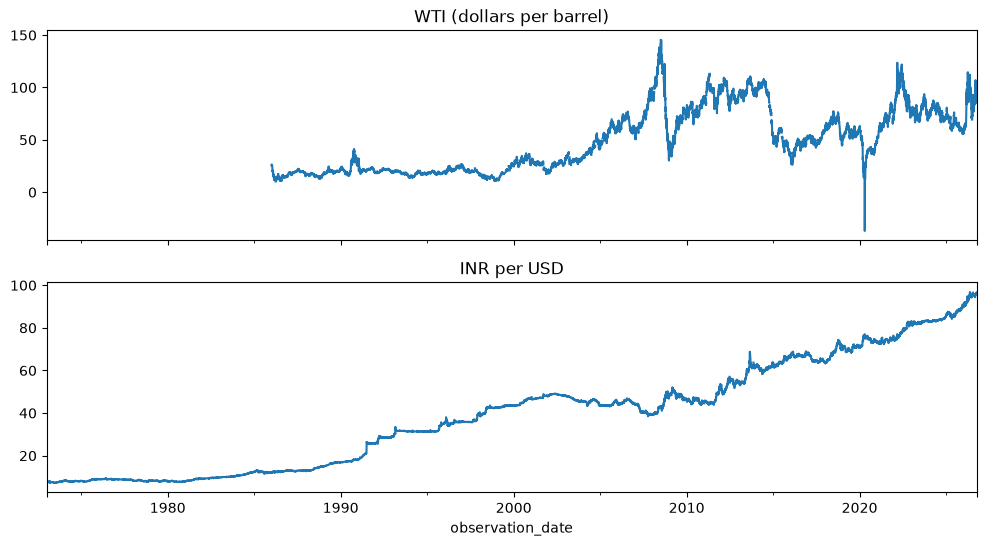

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
oil.plot(ax=axes[0], title="WTI (dollars per barrel)")
fx.plot(ax=axes[1], title="INR per USD")
plt.show()

In [4]:
both = pd.concat([oil, fx], axis=1)
print("rows before dropping missing:", len(both))
both = both.dropna()
print("rows with both values:", len(both))

both["inr_per_barrel"] = both["DCOILWTICO"] * both["DEXINUS"]
both["inr_per_litre"] = both["inr_per_barrel"] / 159   # one barrel is about 159 litres
both.tail()

rows before dropping missing: 14032
rows with both values: 9409


/tmp/ipykernel_191767/1576826700.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  both = pd.concat([oil, fx], axis=1)


,DCOILWTICO,DEXINUS,inr_per_barrel,inr_per_litre
observation_date,,,,
2026-10-05,96.13,96.29,9256.3577,58.216086
2026-10-06,96.24,96.42,9279.4608,58.361389
2026-10-07,95.02,96.76,9194.1352,57.824750
2026-10-08,98.26,96.78,9509.6028,59.808823
2026-10-09,98.73,96.73,9550.1529,60.063855


In [5]:
low, high = 83 * 0.9, 83 * 1.1
fx_clean = fx.dropna()
outside = (fx_clean < low) | (fx_clean > high)
print(f"band: {low:.1f} to {high:.1f}")
print("readings outside the band:", int(outside.sum()), "of", len(fx_clean))
print("first date outside:", fx_clean[outside].index.min())
print(fx_clean.tail(5))


band: 74.7 to 91.3
readings outside the band: 12310 of 13478
first date outside: 1973-01-02 00:00:00
observation_date
2026-10-05    96.29
2026-10-06    96.42
2026-10-07    96.76
2026-10-08    96.78
2026-10-09    96.73
Name: DEXINUS, dtype: float64
